# Notebook 01 — A CART classification tree from scratch

**Mathematics & Statistics for Machine Learning — Albert School, MSc 1** · Lucas, Manuel, Amine

**Research question.** Is education the main driver of earning more than $50K a year, or do other factors such as marital status, age and hours worked matter more?

This notebook builds the algorithm step by step: the model, the objective, the split search, the recursive growth, prediction and feature importance. Every function is checked right after it is written (`assert` + `OK`), and the final version is compared with `sklearn.tree.DecisionTreeClassifier`.

The final code lives in `src/cart.py` (NumPy only). This notebook imports it and shows each part, so the code exists only once. scikit-learn is used **only** for the comparison, as the brief allows.

## 0. Setup

In [1]:
import os
from pathlib import Path

# Run from the repository root so that `src` can be imported and `data/` is shared.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import inspect
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

from src.data import SEED, get_splits
from src import cart
from src.cart import CARTClassifier, gini, entropy, split_score, best_split, best_split_naive

np.random.seed(SEED)
def show(f):
    print(inspect.getsource(f))

In [2]:
splits, feature_names = get_splits()
X_train, y_train = splits["X_train"], splits["y_train"]
X_val, y_val = splits["X_val"], splits["y_val"]
print(X_train.shape, f"| share of >50K: {y_train.mean():.3f}")

(29304, 91) | share of >50K: 0.239


## 1. The model: a tree of yes/no rules

A classification tree asks a sequence of yes/no questions of the form $x_j \le s$ ("is age $\le$ 30?"). Each internal node holds one rule, each leaf holds the share of each class among the training points that reach it.

Formally, the tree splits the feature space into $M$ disjoint rectangles $R_1, \dots, R_M$ (the leaves). In leaf $R_m$, with $n_m$ training points, the class proportions are
$$p_{mk} = \frac{1}{n_m} \sum_{x_i \in R_m} \mathbb 1(y_i = k), \qquad \hat y(x) = \arg\max_k p_{mk} \quad \text{for } x \in R_m .$$

The figure below shows the rectangles drawn by a depth-3 tree using only age and hours per week.

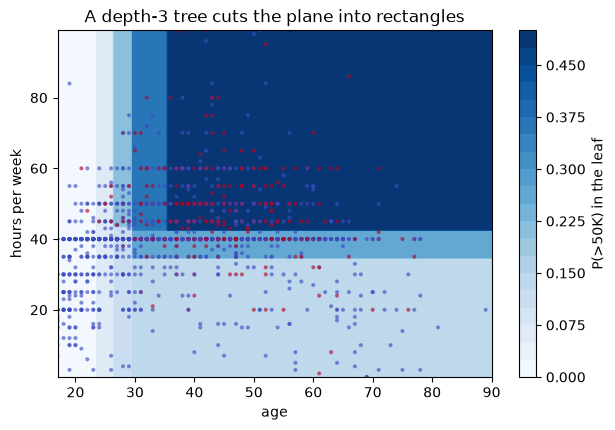

age <= 29.50  (n=29304, gini=0.364)
|   age <= 26.50  (n=8675, gini=0.099)
|   |   age <= 23.50  (n=6434, gini=0.047)
|   |   |   leaf: n=4358, P(>50K)=0.01
|   |   age >  23.50
|   |   |   leaf: n=2076, P(>50K)=0.06
|   age >  26.50
|   |   hours-per-week <= 43.50  (n=2241, gini=0.231)
|   |   |   leaf: n=1558, P(>50K)=0.10
|   |   hours-per-week >  43.50
|   |   |   leaf: n=683, P(>50K)=0.21
age >  29.50
|   hours-per-week <= 42.50  (n=20629, gini=0.434)
|   |   hours-per-week <= 34.50  (n=13740, gini=0.370)
|   |   |   leaf: n=2459, P(>50K)=0.14
|   |   hours-per-week >  34.50
|   |   |   leaf: n=11281, P(>50K)=0.27
|   hours-per-week >  42.50
|   |   age <= 35.50  (n=6889, gini=0.497)
|   |   |   leaf: n=1590, P(>50K)=0.36
|   |   age >  35.50
|   |   |   leaf: n=5299, P(>50K)=0.49


In [3]:
i_age, i_hours = feature_names.index("age"), feature_names.index("hours-per-week")
X2 = X_train[:, [i_age, i_hours]]
tree2 = CARTClassifier(max_depth=3).fit(X2, y_train)

ages, hours = np.meshgrid(np.linspace(17, 90, 300), np.linspace(1, 99, 300))
grid = np.c_[ages.ravel(), hours.ravel()]
proba = tree2.predict_proba(grid)[:, 1].reshape(ages.shape)

fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(ages, hours, proba, levels=20, cmap="Blues")
idx = np.random.default_rng(SEED).choice(len(X2), 1500, replace=False)
ax.scatter(*X2[idx].T, c=y_train[idx], cmap="coolwarm", s=4, alpha=0.5)
fig.colorbar(cs, label="P(>50K) in the leaf")
ax.set(xlabel="age", ylabel="hours per week", title="A depth-3 tree cuts the plane into rectangles")
plt.show()
tree2.print_tree(["age", "hours-per-week"])

## 2. The objective: Gini impurity

A good leaf is **pure** (Lecture 3B, slide 11: "make the groups pure"): almost all of its points belong to one class. The Gini impurity measures how mixed a node is:
$$G = 1 - \sum_k p_k^2 .$$
Reading it (Lecture 3B, slide 12): pick two points at random in the node; $G$ is the chance that they have different labels. It is 0 for a pure node and reaches its maximum $1 - 1/K$ for a uniform node: **0.5** with two classes. At the root of Adult, $G \approx 1 - (0.76^2 + 0.24^2) \approx 0.36$.

The entropy $H = -\sum_k p_k \log_2 p_k$ is the other classical choice (maximum 1 bit at 50/50). Both curves have the same shape; we use Gini by default, like scikit-learn, because it needs no logarithm and gives almost the same trees.

In [4]:
show(gini); show(entropy)

def gini(y):
    """Gini impurity of a label vector: 1 - sum_k p_k^2."""
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    p = np.bincount(y) / y.size
    return 1.0 - np.sum(p ** 2)

def entropy(y):
    """Entropy of a label vector: - sum_k p_k log2 p_k."""
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    p = np.bincount(y) / y.size
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))



In [5]:
# Checkpoint
assert gini(np.array([0, 0, 0, 0])) == 0
assert np.isclose(gini(np.array([0, 0, 1, 1])), 0.5)
assert np.isclose(gini(np.array([0, 1, 1, 1])), 0.375)
assert np.isclose(entropy(np.array([0, 0, 1, 1])), 1.0)
print(f"Gini at the root of Adult: {gini(y_train):.4f}")
print("OK")

Gini at the root of Adult: 0.3641
OK


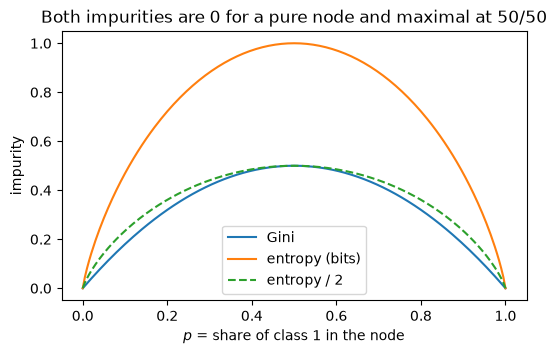

In [6]:
p = np.linspace(0, 1, 201)
g = 1 - p**2 - (1 - p)**2
h = -np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0) - np.where(p < 1, (1 - p) * np.log2(np.where(p < 1, 1 - p, 1)), 0)
plt.figure(figsize=(6, 3.5))
plt.plot(p, g, label="Gini")
plt.plot(p, h, label="entropy (bits)")
plt.plot(p, h / 2, "--", label="entropy / 2")
plt.xlabel("$p$ = share of class 1 in the node"); plt.ylabel("impurity"); plt.legend()
plt.title("Both impurities are 0 for a pure node and maximal at 50/50")
plt.show()

## 3. Scoring a split

A split sends $n_L$ points to the left child and $n_R$ to the right. Its quality is the **size-weighted** impurity of the two children:
$$G_{split} = \frac{n_L}{n} G_L + \frac{n_R}{n} G_R, \qquad \text{gain} = G_{parent} - G_{split}.$$
We keep the split with the smallest $G_{split}$. Weighting by size matters: without it, a split that isolates one single point (a pure child with $G=0$) would look excellent while it barely changes anything.

**Exercise 3B.1 of the lecture (slide 14), by hand.** Ten clients, 6 repaid (R) and 4 defaulted (D):

| client | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| income | 45 | 60 | 38 | 52 | 70 | 25 | 20 | 28 | 15 | 22 |
| age | 50 | 45 | 28 | 35 | 30 | 55 | 42 | 25 | 33 | 38 |
| label | R | R | R | R | R | R | D | D | D | D |

1. Root: $G = 1 - 0.6^2 - 0.4^2 = 1 - 0.36 - 0.16 = 0.48$.
2. Question A, "income > 30?": yes = clients 1–5 (5 R, 0 D), $G = 0$; no = clients 6–10 (1 R, 4 D), $G = 1 - 0.2^2 - 0.8^2 = 0.32$. $G_{split} = \frac{5}{10}\cdot 0 + \frac{5}{10}\cdot 0.32 = 0.16$.
   Question B, "age > 40?": yes = clients 1, 2, 6, 7 (3 R, 1 D), $G = 1 - 0.75^2 - 0.25^2 = 0.375$; no = the other 6 (3 R, 3 D), $G = 0.5$. $G_{split} = \frac{4}{10}\cdot 0.375 + \frac{6}{10}\cdot 0.5 = 0.45$.
3. The tree chooses **A**: impurity drops from 0.48 to 0.16, a gain of **0.32** (B only gains 0.03).

Below, the same numbers by code, then our `best_split` searches *all* thresholds of both features: it must find the income question (threshold 33 = midpoint between 28 and 38, i.e. the same partition as "income > 30").

In [7]:
show(split_score)

def split_score(y_left, y_right, criterion="gini"):
    """Weighted impurity of a split: n_L/n * G_L + n_R/n * G_R."""
    impurity = gini if criterion == "gini" else entropy
    n_left, n_right = len(y_left), len(y_right)
    n = n_left + n_right
    return n_left / n * impurity(y_left) + n_right / n * impurity(y_right)



In [8]:
# Checkpoint: exercise 3B.1
income = np.array([45, 60, 38, 52, 70, 25, 20, 28, 15, 22])
age = np.array([50, 45, 28, 35, 30, 55, 42, 25, 33, 38])
label = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1])        # 1 = defaulted
g_root = gini(label)
g_A = split_score(label[income > 30], label[income <= 30])
g_B = split_score(label[age > 40], label[age <= 40])
print(f"root {g_root:.3f} | A: G_split = {g_A:.3f} (gain {g_root - g_A:.3f}) | B: G_split = {g_B:.3f} (gain {g_root - g_B:.3f})")
assert np.isclose(g_root, 0.48) and np.isclose(g_A, 0.16) and np.isclose(g_B, 0.45)

j, s_, score = best_split(np.c_[income, age].astype(float), label, n_classes=2)
print(f"best_split over all thresholds: {['income', 'age'][j]} <= {s_} (G_split = {score:.3f})")
assert j == 0 and s_ == 33.0 and np.isclose(score, 0.16)
print("OK")

root 0.480 | A: G_split = 0.160 (gain 0.320) | B: G_split = 0.450 (gain 0.030)
best_split over all thresholds: income <= 33.0 (G_split = 0.160)
OK


## 4. Finding the best split

**Which thresholds?** Between two consecutive distinct values $a < b$ of a feature, every threshold gives the same partition of the training points. Testing one per gap is enough; like scikit-learn we take the midpoint $(a+b)/2$, which is also the most neutral choice for new points. A feature with $u$ distinct values gives $u-1$ candidates.

**Naive search.** For each feature and each midpoint, split the data and compute $G_{split}$. Each evaluation costs $O(n)$ and there are up to $n$ thresholds per feature: $O(d \cdot n^2)$.

**Vectorised search.** Sort the values of the feature once. Going from one threshold to the next moves **one** point from right to left, so the class counts on the left of every threshold are just the **cumulative sums** of the one-hot labels; the right counts are total − left. All the $G_{split}$ of one feature are then computed in one NumPy operation: $O(d \cdot n \log n)$, dominated by the sort.

`min_samples_leaf` simply removes the thresholds that would leave fewer points than allowed in a child.

In [9]:
show(best_split_naive)

def best_split_naive(X, y, min_samples_leaf=1, criterion="gini"):
    """Reference version with plain loops: for every feature and every midpoint,
    split the data and score it. O(d * n^2). Returns (feature, threshold, score)
    or None. Used to check the vectorised version, not for training."""
    n, d = X.shape
    best = None
    for j in range(d):
        values = np.unique(X[:, j])
        for a, b in zip(values[:-1], values[1:]):
            if b <= a + FEATURE_THRESHOLD:
                continue
            threshold = (a + b) / 2
            mask = X[:, j] <= threshold
            n_left = mask.sum()
            if n_left < min_samples_leaf or n - n_left < min_samples_leaf:
                continue
            score = split_score(y[mask], y[~mask], criterion)
            if best is None or score < best[2]:
                best = (j, threshold, score)
    return best



In [10]:
show(best_split)

def best_split(X, y, n_classes, min_samples_leaf=1, criterion="gini"):
    """Vectorised search of the best split. Returns (feature, threshold, score)
    or None if no valid split exists.

    For each feature: sort the values once, then cumulative sums of the one-hot
    labels give the class counts on the left of every threshold at once (right =
    total - left). Cost O(d * n log n) instead of O(d * n^2).
    """
    n, d = X.shape
    onehot = np.eye(n_classes)[y]                     # (n, K)
    total = onehot.sum(axis=0)                        # (K,)
    best = None
    for j in range(d):
        order = np.argsort(X[:, j], kind="stable")
        x = X[order, j]
        left = np.cumsum(onehot[order], axis=0)[:-1]  # counts left of position i+1
        right = total - left
        n_left = np.arange(1, n)
        # Candidate positions: between two distinct values, both leaves big enough.
        valid = (x[1:] > x[:-1] + FEATURE_THRESHOLD) \
            & (n_left >= min_samples_

In [11]:
# Checkpoint: naive == vectorised on random data (ties can pick another threshold with the same score)
rng = np.random.default_rng(SEED)
for _ in range(50):
    A = rng.integers(0, 10, size=(120, 4)).astype(float)
    b = rng.integers(0, 2, size=120)
    naive, fast = best_split_naive(A, b, 2), best_split(A, b, 2, 2)
    assert np.isclose(naive[2], fast[2])
print("OK")

OK


In [12]:
# Checkpoint: same first split as DecisionTreeClassifier(max_depth=1) on Adult
ours = CARTClassifier(max_depth=1).fit(X_train, y_train)
ref = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train, y_train)
print(f"ours   : {feature_names[ours.root_.feature]} <= {ours.root_.threshold:.3f}")
print(f"sklearn: {feature_names[ref.tree_.feature[0]]} <= {ref.tree_.threshold[0]:.3f}")
assert ours.root_.feature == ref.tree_.feature[0]
assert np.isclose(ours.root_.threshold, ref.tree_.threshold[0])
print("OK")

ours   : marital-status_Married-civ-spouse <= 0.500
sklearn: marital-status_Married-civ-spouse <= 0.500
OK


In [13]:
# Timing: naive vs vectorised. Continuous features (all values distinct) are the worst case of the naive search.
rows = []
for n in [250, 500, 1000, 2000, 4000]:
    A = np.random.default_rng(SEED).normal(size=(n, 5))
    b = (A[:, 0] + np.random.default_rng(SEED + 1).normal(size=n) > 0).astype(int)
    t = time.perf_counter(); best_split_naive(A, b); t_naive = time.perf_counter() - t
    t = time.perf_counter(); best_split(A, b, 2); t_fast = time.perf_counter() - t
    rows.append({"n": n, "naive (s)": t_naive, "vectorised (s)": t_fast, "speed-up": t_naive / t_fast})
timing = pd.DataFrame(rows)
display(timing.round(4))

,n,naive (s),vectorised (s),speed-up
0,250,0.0069,0.0002,36.8669
1,500,0.0165,0.0003,61.9406
2,1000,0.0456,0.0005,89.5283
3,2000,0.1401,0.0009,155.2947
4,4000,0.5133,0.0018,284.6156


With all values distinct, the naive time grows about 3–4× each time $n$ doubles (quadratic), the vectorised one about 2× (quasi-linear), so the speed-up keeps growing with $n$. On Adult's real features the naive search suffers less, because most columns have few distinct values (one-hot columns have only one threshold).

## 5. Growing the tree recursively

The tree is grown **greedily**: find the best split of the node, apply it, and start again in each child. It is greedy because finding the globally optimal tree is NP-hard; each choice is only the best *locally*, and a split that looks weak now can never be "unlocked" by a later one (the classic XOR case).

A node becomes a leaf when one of these rules fires:
- `max_depth` is reached;
- it has fewer than `min_samples_split` points, or fewer than `2 × min_samples_leaf`;
- it is pure ($G = 0$): nothing left to separate;
- no valid threshold exists (all features constant in the node);
- the weighted decrease $\frac{N_t}{N}(G_t - G_{split})$ is below `min_impurity_decrease` (pre-pruning).

In [14]:
show(CARTClassifier._build)

    def _build(self, X, y, depth):
        """Greedy recursive growth. Stops on max_depth, min_samples_split,
        min_samples_leaf, pure node or impurity decrease < min_impurity_decrease."""
        n = len(y)
        counts = np.bincount(y, minlength=self.n_classes_).astype(float)
        node = Node(proba=counts / n, n_samples=n,
                    impurity=float(_impurity_from_counts(counts, self.criterion)))

        if ((self.max_depth is not None and depth >= self.max_depth)
                or n < self.min_samples_split
                or n < 2 * self.min_samples_leaf
                or node.impurity <= EPSILON):
            return node

        split = self._best_split(X, y)
        if split is None:
            return node
        feature, threshold, score = split
        decrease = n / self._n_total * (node.impurity - score)
        if decrease + EPSILON < self.min_impurity_decrease:
            return node

        mask = X[:, feature] <= threshold
        node.feature, 

In [15]:
tree3 = CARTClassifier(max_depth=3).fit(X_train, y_train)
tree3.print_tree(feature_names)

marital-status_Married-civ-spouse <= 0.50  (n=29304, gini=0.364)
|   capital-gain <= 7055.50  (n=15946, gini=0.119)
|   |   education-num <= 12.50  (n=15678, gini=0.092)
|   |   |   leaf: n=12577, P(>50K)=0.02
|   |   education-num >  12.50
|   |   |   leaf: n=3101, P(>50K)=0.15
|   capital-gain >  7055.50
|   |   age <= 20.50  (n=268, gini=0.079)
|   |   |   leaf: n=5, P(>50K)=0.20
|   |   age >  20.50
|   |   |   leaf: n=263, P(>50K)=0.97
marital-status_Married-civ-spouse >  0.50
|   education-num <= 11.50  (n=13358, gini=0.495)
|   |   capital-gain <= 5095.50  (n=8915, gini=0.439)
|   |   |   leaf: n=8500, P(>50K)=0.29
|   |   capital-gain >  5095.50
|   |   |   leaf: n=415, P(>50K)=0.98
|   education-num >  11.50
|   |   capital-gain <= 5095.50  (n=4443, gini=0.422)
|   |   |   leaf: n=3812, P(>50K)=0.65
|   |   capital-gain >  5095.50
|   |   |   leaf: n=631, P(>50K)=1.00


In [16]:
# Checkpoint: an unlimited tree fits the training set perfectly (except identical rows with different labels)
deep = CARTClassifier().fit(X_train, y_train)
train_acc = (deep.predict(X_train) == y_train).mean()
_, inv = np.unique(X_train, axis=0, return_inverse=True)
conflicts = pd.Series(y_train).groupby(inv.ravel()).nunique().gt(1).sum()
print(f"depth {deep.get_depth()}, {deep.get_n_leaves()} leaves, train accuracy {train_acc:.4f}")
print(f"groups of identical rows with both labels: {conflicts} -> no tree can separate them")
assert train_acc > 0.97
print("OK")

depth 54, 5137 leaves, train accuracy 0.9777
groups of identical rows with both labels: 528 -> no tree can separate them
OK


The unlimited tree reaches a depth above 50 with thousands of leaves: it has memorised the training set, including its noise. This is overfitting, and why the depth is tuned on the validation set in notebook 02.

## 6. Prediction

To predict, an observation goes down from the root: at each node, left if $x_j \le s$, right otherwise, until a leaf. `predict_proba` returns the class proportions of that leaf, `predict` the majority class. Our implementation routes all rows at once: at each node, a boolean mask splits the indices between the two children.

In [17]:
show(CARTClassifier.predict_proba)

    def predict_proba(self, X):
        """Sends every row down the tree (vectorised by node) and returns the leaf proportions."""
        X = np.asarray(X, dtype=np.float32).astype(np.float64)
        out = np.empty((len(X), self.n_classes_))

        def route(node, idx):
            if node.is_leaf:
                out[idx] = node.proba
                return
            mask = X[idx, node.feature] <= node.threshold
            route(node.left, idx[mask])
            route(node.right, idx[~mask])

        route(self.root_, np.arange(len(X)))
        return out



In [18]:
# Checkpoint: same predictions as scikit-learn for depths 1 to 6
for depth in range(1, 7):
    ours = CARTClassifier(max_depth=depth).fit(X_train, y_train)
    ref = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_train, y_train)
    agree = (ours.predict(X_val) == ref.predict(X_val)).mean()
    print(f"depth {depth}: agreement on validation = {agree:.4%}, leaves {ours.get_n_leaves()} vs {ref.get_n_leaves()}")
    assert agree > 0.999
print("OK")

depth 1: agreement on validation = 100.0000%, leaves 2 vs 2


depth 2: agreement on validation = 100.0000%, leaves 4 vs 4


depth 3: agreement on validation = 100.0000%, leaves 8 vs 8


depth 4: agreement on validation = 100.0000%, leaves 16 vs 16


depth 5: agreement on validation = 99.9898%, leaves 30 vs 30


depth 6: agreement on validation = 99.9898%, leaves 51 vs 51
OK


When agreement is not exactly 100 %, it is a **tie**: two features give exactly the same $G_{split}$ (frequent with one-hot columns). scikit-learn visits features in a random order and keeps the first best one it meets; we visit them in column order. Both choices are equally optimal for the objective.

## 7. Feature importance

The importance of feature $j$ is the total impurity decrease it brings, weighted by the share of points of each node that uses it:
$$I_j = \sum_{t \,:\, \text{split on } j} \frac{N_t}{N}\Big(G_t - \frac{N_{t,L}}{N_t}G_{t,L} - \frac{N_{t,R}}{N_t}G_{t,R}\Big), \qquad \text{then } I_j \leftarrow I_j / \textstyle\sum_k I_k .$$
It is computed on the training set and favours features with many possible thresholds (continuous ones) — a bias to keep in mind when answering the research question.

In [19]:
show(CARTClassifier._compute_importances)

    def _compute_importances(self):
        """Sum over the nodes using feature j of (N_t/N)·(G_t - G_split), normalised to 1."""
        imp = np.zeros(self.n_features_in_)

        def visit(node):
            if node.is_leaf:
                return
            w = lambda c: c.n_samples / self._n_total * c.impurity
            imp[node.feature] += w(node) - w(node.left) - w(node.right)
            visit(node.left)
            visit(node.right)

        visit(self.root_)
        return imp / imp.sum() if imp.sum() > 0 else imp



In [20]:
# Checkpoint: close to DecisionTreeClassifier.feature_importances_
ours = CARTClassifier(max_depth=6).fit(X_train, y_train)
ref = DecisionTreeClassifier(max_depth=6, random_state=SEED).fit(X_train, y_train)
diff = np.abs(ours.feature_importances_ - ref.feature_importances_).max()
print(f"max absolute difference: {diff:.5f}")
assert diff < 0.01
top = pd.DataFrame({"ours": ours.feature_importances_, "sklearn": ref.feature_importances_}, index=feature_names)
display(top.sort_values("ours", ascending=False).head(8).round(4))
print("OK")

max absolute difference: 0.00069


,ours,sklearn
marital-status_Married-civ-spouse,0.4512,0.4514
education-num,0.2228,0.2229
capital-gain,0.1994,0.1987
capital-loss,0.0721,0.0717
age,0.0293,0.0294
hours-per-week,0.0213,0.0213
relationship_Wife,0.0027,0.0027
workclass_Self-emp-not-inc,0.0007,0.0007


OK


## 8. Pruning (option): cost-complexity

Instead of stopping early, one can grow a full tree and **prune** it. For a subtree $T_t$ rooted at node $t$, let $R(t) = \frac{N_t}{N}G_t$ and $R(T_t)$ the sum over its leaves. Collapsing $T_t$ into a leaf costs $R(t) - R(T_t)$ and saves $|T_t| - 1$ leaves, so its "price per leaf" is
$$g(t) = \frac{R(t) - R(T_t)}{|T_t| - 1}.$$
Weakest-link pruning repeatedly collapses the node with the smallest $g(t)$ while $g(t) \le \alpha$ (`ccp_alpha`).

In [21]:
for alpha in [0.0002, 0.0005, 0.001]:
    ours = CARTClassifier(ccp_alpha=alpha).fit(X_train, y_train)
    ref = DecisionTreeClassifier(ccp_alpha=alpha, random_state=SEED).fit(X_train, y_train)
    print(f"alpha={alpha}: leaves {ours.get_n_leaves()} vs {ref.get_n_leaves()}, "
          f"agreement {(ours.predict(X_val) == ref.predict(X_val)).mean():.4%}")

alpha=0.0002: leaves 56 vs 56, agreement 100.0000%


alpha=0.0005: leaves 26 vs 26, agreement 100.0000%


alpha=0.001: leaves 17 vs 17, agreement 100.0000%


## 9. Summary

| Part | Function in `src/cart.py` | Checked against |
|---|---|---|
| Objective | `gini`, `entropy`, `split_score` | known values, exercise 3B.1 of the lecture |
| Split search | `best_split_naive`, `best_split` (vectorised) | each other; first split of sklearn |
| Growth | `CARTClassifier._build` (greedy, 5 stopping rules) | perfect fit of the train set when unlimited |
| Prediction | `predict_proba`, `predict` | sklearn, depths 1–6 |
| Importance | `_compute_importances` | `feature_importances_` |
| Pruning | `_prune` (weakest link) | number of leaves of sklearn |

The same checks run automatically with `uv run pytest`.

**Limits seen so far.** (1) The tree is greedy: it cannot see a good split hidden behind a bad one. (2) Without a limit, it memorises the training set. (3) Our pure-Python recursion is slower than scikit-learn's compiled Cython code (notebook 02, section 6). (4) Ties between features are broken by column order: on near-equal features the tree structure can change, a first sign of the instability studied in notebook 02.